<a href="https://colab.research.google.com/github/pedroasbarbosa31-bot/metodos-numericos-EDO/blob/main/Controle_de_temperatura.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# Tanque de armazenamento com controle de temperatura utilizando vapor
import numpy as np
import matplotlib.pyplot as plt

# Dados
cp = 1 #kcal/kg/°C
Kc = 1 #kcal/min/°C
m = 50 # kg
T0 = 20 # °C
Tsp = 40 # °C
w = 250 # kg/min
ws0 = 9.31 # kg/min
lamb = 537 # kcal/kg
taus = 0.3 # min
taui = 5 # min
taub = 0.1 # min

# Equações
def fun (t, y):
  T, Ts, Tb, I = y
  e = Tsp - y[1]
  ws = ws0 + Kc*e + (Kc/taui)*I
  dT_dt = (w*cp*(T0 - T) + ws*lamb)/ (m*cp)
  dTs_dt = (Tb - Ts)/taus
  dTb_dt = (T - Tb)/taub
  dI_dt = e
  return np.array([dT_dt, dTs_dt, dTb_dt, dI_dt])


In [6]:
# Euler explicito

y0 = [20, 20, 20, 0]

def Euler(fun, y0):
  t = np.linspace(0, 15, 1501)
  y = np.zeros((len(t), len(y0)))

  y[0] = y0

  for i in range(len(t) - 1):
    h = t[i+1] - t[i]
    y[i+1] = y[i] + h * fun(t[i], y[i])
  return t, y

h = 1

t, y = Euler(fun, y0)

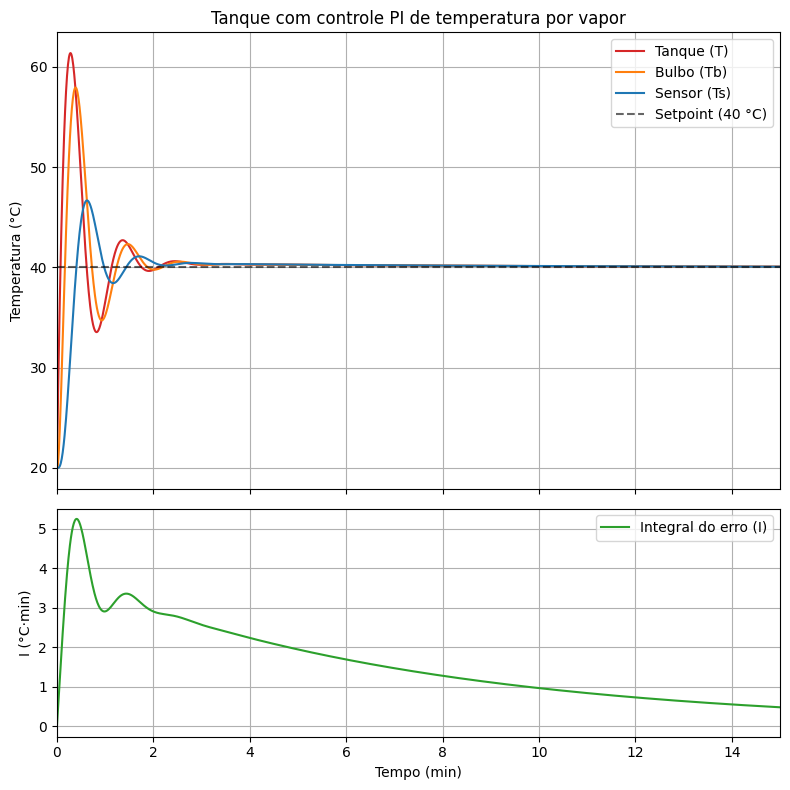

In [7]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 8), sharex=True,
                               gridspec_kw={'height_ratios': [3, 1.5]})

ax1.plot(t, y[:, 0], color='tab:red',    label='Tanque (T)')
ax1.plot(t, y[:, 2], color='tab:orange', label='Bulbo (Tb)')
ax1.plot(t, y[:, 1], color='tab:blue',   label='Sensor (Ts)')
ax1.axhline(Tsp, color='k', linestyle='--', alpha=0.6, label='Setpoint (40 °C)')
ax1.set_ylabel('Temperatura (°C)')
ax1.set_title('Tanque com controle PI de temperatura por vapor')
ax1.legend(); ax1.grid(True)

ax2.plot(t, y[:, 3], color='tab:green', label='Integral do erro (I)')
ax2.set_xlabel('Tempo (min)')
ax2.set_ylabel('I (°C·min)')
ax2.set_xlim(0, 15)
ax2.legend(); ax2.grid(True)

plt.tight_layout()
plt.show()